# Enriched Music Charts Analysis — 2026-W46


In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

from scipy.stats import gaussian_kde
from IPython.display import display, Markdown

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12
plt.rcParams["figure.dpi"] = 100

YT_RED = "#FF0000"
YT_RED_DARK = "#CC0000"
YT_BG = "#FFFFFF"
YT_SURFACE = "#F9F9F9"
YT_TEXT = "#0F0F0F"
YT_GRAY = "#606060"
YT_GRID = "#E5E5E5"


def format_number(x):
    if pd.isna(x):
        return "N/A"
    if x >= 1_000_000_000:
        return f"{x / 1_000_000_000:.1f}B"
    if x >= 1_000_000:
        return f"{x / 1_000_000:.1f}M"
    if x >= 1_000:
        return f"{x / 1_000:.1f}K"
    return f"{x:,.0f}"


def get_continent(country):
    continents = {
        'North America': ['United States', 'Mexico', 'Canada', 'Puerto Rico'],
        'South America': ['Brazil', 'Argentina', 'Colombia', 'Chile', 'Peru', 'Venezuela'],
        'Europe': ['United Kingdom', 'Sweden', 'Germany', 'France', 'Spain', 'Italy', 'Netherlands', 'Turkey'],
        'Asia': ['India', 'South Korea', 'Japan', 'China', 'Indonesia', 'Pakistan', 'Philippines', 'Thailand', 'Vietnam'],
        'Africa': ['Nigeria', 'South Africa', 'Kenya', 'Ghana'],
        'Oceania': ['Australia', 'New Zealand'],
        'Middle East': ['Israel', 'UAE', 'Saudi Arabia']
    }
    for continent, countries in continents.items():
        if country in countries:
            return continent
    return 'Other'


# Metric functions: try to import from the package, fall back to inline.
try:
    from core.metrics import (
        collaborations,
        general_stats,
        genre_stats,
        top_countries,
        top_countries_by_likes,
        top_songs,
        top_songs_by_country,
        video_metrics,
    )
except ImportError:
    # Self-contained fallback so the notebook runs when moved or opened
    # outside the repository (e.g. Colab).
    def general_stats(df):
        return {
            "total_songs": int(len(df)),
            "unique_countries": int(df["artist_country"].nunique()),
            "unique_genres": int(df["macro_genre"].nunique()),
            "total_views": int(df["views"].sum()),
            "total_likes": int(df["likes"].sum()),
            "total_comments": int(df["comment_count"].sum()),
            "avg_views": float(df["views"].mean()),
            "avg_likes": float(df["likes"].mean()),
            "avg_engagement": float(df["engagement"].mean()),
        }

    def top_countries(df, n=10):
        return (
            df.groupby("artist_country")
            .agg(total_songs=("rank", "count"), total_views=("views", "sum"))
            .reset_index()
            .sort_values("total_songs", ascending=False)
            .head(n)
            .reset_index(drop=True)
        )

    def top_countries_by_likes(df, n=10):
        return (
            df.groupby("artist_country")["likes"]
            .sum()
            .reset_index()
            .rename(columns={"likes": "total_likes"})
            .sort_values("total_likes", ascending=False)
            .head(n)
            .reset_index(drop=True)
        )

    def top_songs_by_country(df, country, metric="views", n=5):
        cols = ["track_name", "artist_names", "views", "likes", "engagement"]
        return (
            df[df["artist_country"] == country]
            .nlargest(n, metric)[cols]
            .reset_index(drop=True)
        )

    def genre_stats(df):
        out = (
            df.groupby("macro_genre")
            .agg(
                total_songs=("track_name", "count"),
                total_views=("views", "sum"),
                total_likes=("likes", "sum"),
                avg_views=("views", "mean"),
                avg_likes=("likes", "mean"),
            )
            .reset_index()
        )
        out["engagement_rate"] = (
            out["total_likes"] / out["total_views"].replace(0, pd.NA) * 100
        ).fillna(0).round(2)
        return out.sort_values("total_songs", ascending=False).reset_index(drop=True)

    def video_metrics(df):
        flags = {
            "Official": "is_official_video",
            "Lyric": "is_lyric_video",
            "Live": "is_live_performance",
        }
        rows = []
        total = len(df)
        for label, flag in flags.items():
            subset = df[df[flag] == 1]
            rows.append({
                "video_type": label,
                "count": int(len(subset)),
                "pct": float(len(subset) / total * 100) if total else 0.0,
                "avg_views": float(subset["views"].mean()) if len(subset) else 0.0,
                "avg_engagement": float(subset["engagement"].mean()) if len(subset) else 0.0,
            })
        return pd.DataFrame(rows)

    def top_songs(df, metric="views", n=10):
        cols = ["rank", "track_name", "artist_names", metric, "artist_country"]
        return df.nlargest(n, metric)[cols].reset_index(drop=True)

    def collaborations(df):
        grouped = (
            df.groupby("is_collaboration")
            .agg(
                count=("track_name", "count"),
                avg_views=("views", "mean"),
                avg_engagement=("engagement", "mean"),
            )
            .reset_index()
        )
        grouped["is_collaboration"] = grouped["is_collaboration"].map(
            {0: "Solo", 1: "Collaboration"}
        )
        return grouped


DB_PATH = Path("../../charts_archive/3_enrich-chart-data/youtube_charts_2026-W46_enriched.db")
conn = sqlite3.connect(DB_PATH)
df = pd.read_sql_query("SELECT * FROM enriched_songs", conn)
conn.close()

df["upload_date"] = pd.to_datetime(df["upload_date"], errors="coerce")
df["upload_quarter"] = df["upload_date"].dt.quarter
df["engagement"] = np.where(
    df["views"] > 0, (df["likes"] / df["views"] * 100).round(2), 0.0
)
df["continent"] = df["artist_country"].apply(get_continent)


## 1. Introduction

**Week:** 2026-W46 | **Period:** 2026-11-09 → 2026-11-15 | **Days:** 7

## 2. General Statistics

In [2]:
stats = general_stats(df)
display(pd.DataFrame(list(stats.items()), columns=['Metric', 'Value']))

,Metric,Value
0,total_songs,1.000000e+02
1,unique_countries,2.600000e+01
2,unique_genres,1.700000e+01
3,total_views,1.371256e+09
4,total_likes,2.538234e+08
5,total_comments,1.335579e+07
6,avg_views,1.371256e+07
7,avg_likes,2.538234e+06
8,avg_engagement,2.231440e+01


## 3. Continent Analysis

,continent,total_songs,total_views,total_likes
0,Asia,44,631823604,83866876
2,North America,27,322535014,99818900
1,Europe,12,164454336,17461216
4,Other,11,147562414,42680324
5,South America,5,91900540,9652437
3,Oceania,1,12979743,343677


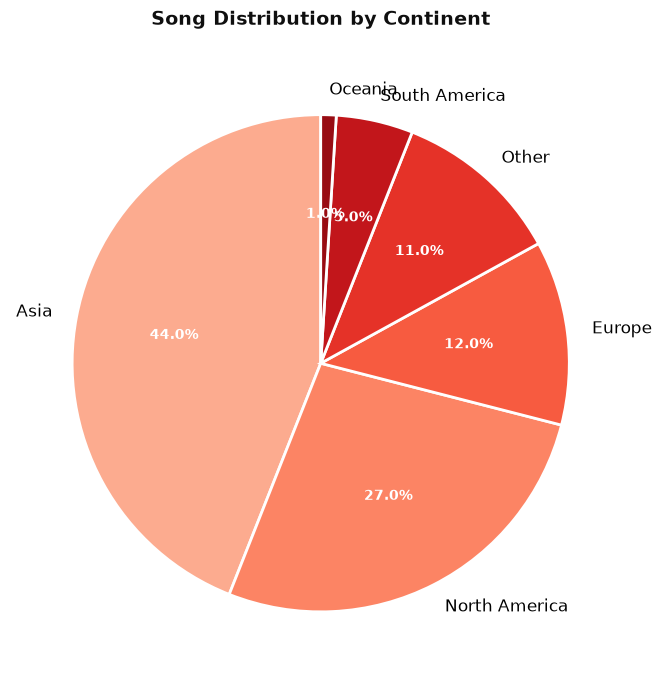

In [3]:
continent_stats = df.groupby('continent').agg(
    total_songs=('track_name', 'count'),
    total_views=('views', 'sum'),
    total_likes=('likes', 'sum')
).reset_index().sort_values('total_songs', ascending=False)
display(continent_stats)

fig, ax = plt.subplots(figsize=(10, 7))
fig.patch.set_facecolor(YT_BG)
colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(continent_stats)))

wedges, texts, autotexts = ax.pie(
    continent_stats['total_songs'],
    labels=continent_stats['continent'],
    autopct='%1.1f%%',
    colors=colors,
    startangle=90,
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(10)

ax.set_title('Song Distribution by Continent', fontweight='bold', color=YT_TEXT, fontsize=14, pad=20)
plt.tight_layout()
plt.show()

## 4. Country Analysis

### 4.1. Top Countries by Song Count

,artist_country,total_songs,total_views,percentage
5,India,31,457694845,38.27
23,United States,18,203085048,22.22
18,South Korea,7,98172618,8.64
22,United Kingdom,6,78605268,7.41
8,Mexico,4,36507577,4.94
1,Brazil,4,51238569,4.94
9,Multi-country,4,50144460,4.94
16,Puerto Rico,3,56568770,3.70
2,Canada,2,26373619,2.47
20,Thailand,2,17880673,2.47


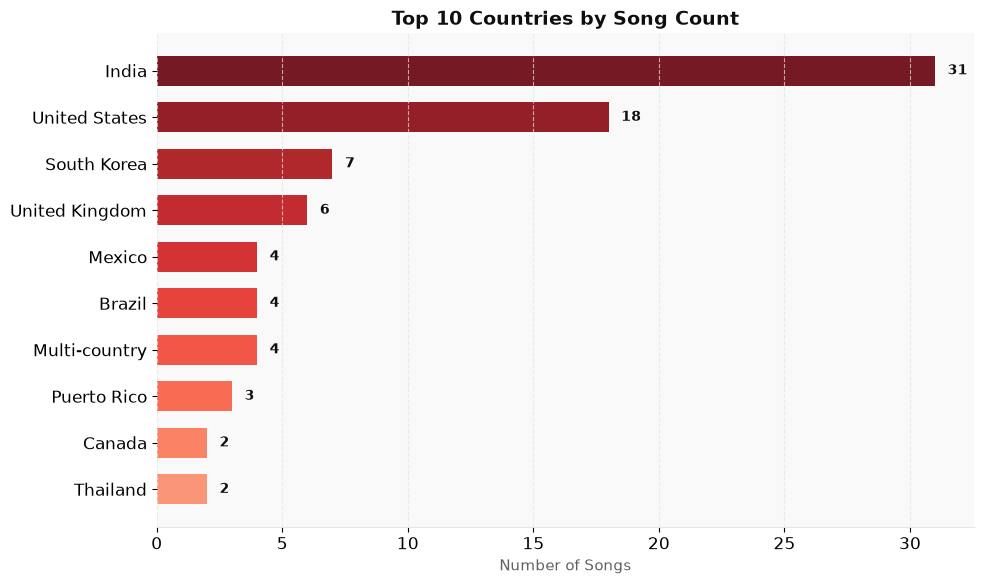

In [4]:
top_countries = (df
    .groupby('artist_country')
    .agg(total_songs=('rank', 'count'), total_views=('views', 'sum'))
    .reset_index()
    .sort_values('total_songs', ascending=False)
    .head(10))
total = top_countries['total_songs'].sum()
top_countries['percentage'] = (top_countries['total_songs'] / total * 100).round(2)
display(top_countries)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_SURFACE)
colors = plt.cm.Reds(np.linspace(0.4, 1, len(top_countries)))[::-1]
bars = ax.barh(top_countries['artist_country'], top_countries['total_songs'],
               color=colors, edgecolor='none', height=0.65, alpha=0.9)
ax.set_xlabel('Number of Songs', fontsize=11, color=YT_GRAY)
ax.set_title('Top 10 Countries by Song Count', fontweight='bold', color=YT_TEXT, fontsize=14)
ax.invert_yaxis()
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color(YT_GRID)
ax.xaxis.grid(True, color=YT_GRID, linestyle='--', alpha=0.7)
for bar, val in zip(bars, top_countries['total_songs']):
    ax.text(val + 0.5, bar.get_y() + bar.get_height()/2, f'{int(val)}',
            va='center', fontsize=10, fontweight='bold', color=YT_TEXT)
plt.tight_layout()
plt.show()

### 4.2. Top Countries by Total Likes

,artist_country,total_likes_fmt
23,United States,82.5M
18,South Korea,38.9M
5,India,37.1M
13,Panama,21.0M
11,Norway,13.5M
4,France,12.2M
2,Canada,11.5M
3,Colombia,8.9M
20,Thailand,4.5M
16,Puerto Rico,4.1M


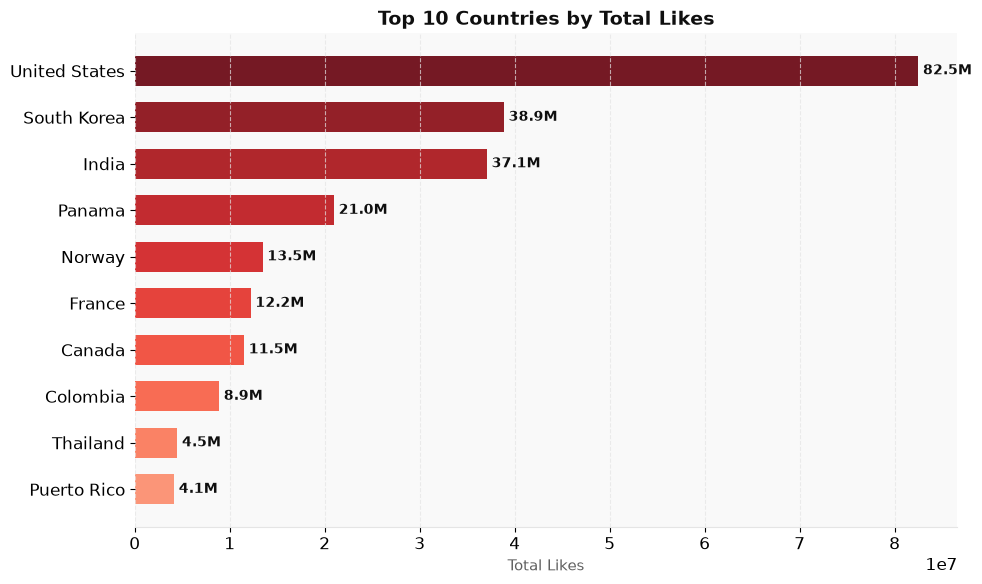

In [5]:
top_likes = (df
    .groupby('artist_country')['likes']
    .sum()
    .reset_index()
    .rename(columns={'likes': 'total_likes'})
    .sort_values('total_likes', ascending=False)
    .head(10))
def format_likes(x):
    if x >= 1_000_000: return f'{x/1_000_000:.1f}M'
    if x >= 1_000: return f'{x/1_000:.1f}K'
    return str(x)
top_likes['total_likes_fmt'] = top_likes['total_likes'].apply(format_likes)
display(top_likes[['artist_country', 'total_likes_fmt']])

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_SURFACE)
colors = plt.cm.Reds(np.linspace(0.4, 1, len(top_likes)))[::-1]
bars = ax.barh(top_likes['artist_country'], top_likes['total_likes'],
               color=colors, edgecolor='none', height=0.65, alpha=0.9)
ax.set_xlabel('Total Likes', fontsize=11, color=YT_GRAY)
ax.set_title('Top 10 Countries by Total Likes', fontweight='bold', color=YT_TEXT, fontsize=14)
ax.invert_yaxis()
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color(YT_GRID)
ax.xaxis.grid(True, color=YT_GRID, linestyle='--', alpha=0.7)
for bar, val in zip(bars, top_likes['total_likes']):
    ax.text(val + 0.5e6, bar.get_y() + bar.get_height()/2,
            format_likes(val), va='center', fontsize=10, fontweight='bold', color=YT_TEXT)
plt.tight_layout()
plt.show()

### 4.3. Top 5 Songs by Country

In [6]:
top_countries_list = df['artist_country'].value_counts().head(10).index.tolist()
for country in top_countries_list:
    display(Markdown(f'**{country}**'))
    df_country = df[df['artist_country'] == country]
    
    top_views = df_country.nlargest(5, 'views')[['track_name', 'artist_names', 'views', 'likes', 'engagement']].copy()
    top_views['views'] = top_views['views'].apply(format_number)
    top_views['likes'] = top_views['likes'].apply(format_number)
    print('   Top 5 by views:')
    display(top_views)
    
    top_likes_country = df_country.nlargest(5, 'likes')[['track_name', 'artist_names', 'views', 'likes', 'engagement']].copy()
    top_likes_country['views'] = top_likes_country['views'].apply(format_number)
    top_likes_country['likes'] = top_likes_country['likes'].apply(format_number)
    print('   Top 5 by likes:')
    display(top_likes_country)

**India**

   Top 5 by views:


,track_name,artist_names,views,likes,engagement
1,Tu Mil Jaaye,Sachin-Jigar & Arijit Singh & Ed Sheeran & Mad...,37.8M,715.8K,1.89
3,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,36.0M,2.2M,6.20
6,गुज़ारिश,Satinder Sartaaj,28.3M,645.3K,2.28
9,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23.5M,2.4M,10.09
10,Barsaat,Banjaare & Roni,23.2M,1.3M,5.79


   Top 5 by likes:


,track_name,artist_names,views,likes,engagement
76,Udaarian,Satinder Sartaaj,9.2M,4.5M,49.00
97,Hookah Bar,Himesh Reshammiya & Vineet Kumar Singh & Aaman...,7.9M,4.1M,52.16
20,Shararat,Shashwat Sachdev & Madhubanti Bagchi & Jasmine...,16.0M,3.1M,19.47
46,Bairan,Banjaare,11.6M,2.6M,22.68
9,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23.5M,2.4M,10.09


**United States**

... (40 outputs left out)

   Top 5 by views:


,track_name,artist_names,views,likes,engagement
22,Save Your Tears,The Weeknd,16.0M,11.1M,69.71
56,Housewife,Tate McRae,10.4M,367.7K,3.54


   Top 5 by likes:


,track_name,artist_names,views,likes,engagement
22,Save Your Tears,The Weeknd,16.0M,11.1M,69.71
56,Housewife,Tate McRae,10.4M,367.7K,3.54


## 5. Genre Analysis

In [7]:
genre_stats = (df
    .groupby('macro_genre')
    .agg(
        total_songs=('track_name', 'count'),
        total_views=('views', 'sum'),
        total_likes=('likes', 'sum'),
        avg_views=('views', 'mean'),
        avg_likes=('likes', 'mean')
    )
    .reset_index()
    .sort_values('total_songs', ascending=False))
genre_stats['engagement_rate'] = (genre_stats['total_likes'] / genre_stats['total_views'] * 100).round(2).fillna(0)
display(genre_stats.head(10)[['macro_genre', 'total_songs', 'engagement_rate']])

,macro_genre,total_songs,engagement_rate
4,Indian Pop,30,7.99
12,Pop,21,25.83
3,Hip-Hop/Rap,8,18.26
7,K-Pop/K-Rock,7,39.58
14,Regional Mexicano,6,9.53
2,Electrónica/Dance,5,26.07
13,Reggaetón/Trap Latino,5,32.61
9,Multi-genre,4,6.58
1,Brazilian Regional,3,1.18
6,J-Pop/J-Rock,2,25.05


### 5.2. Genre Distribution Treemap

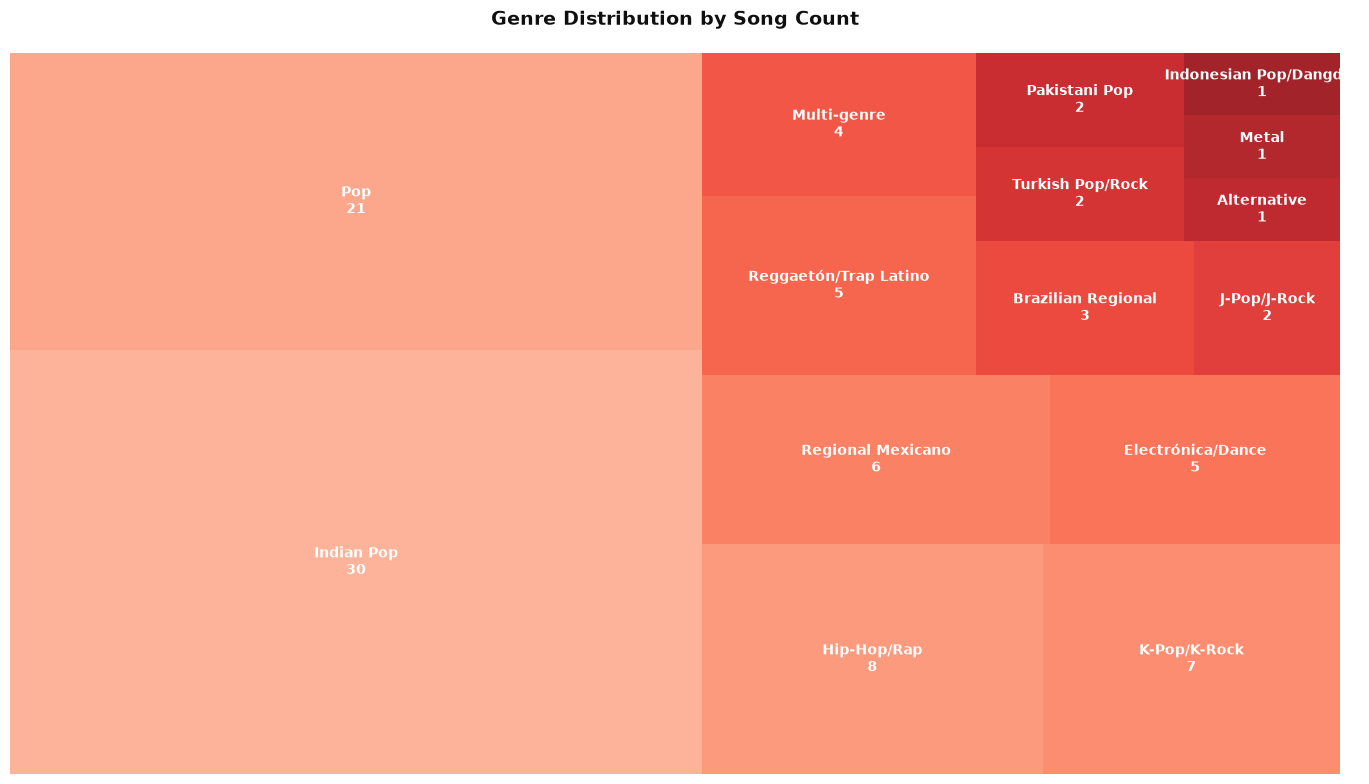

In [8]:
treemap_data = genre_stats.head(15).copy()
sizes = treemap_data['total_songs'].values
labels = [f'{genre}\n{format_number(song_count)}' 
          for genre, song_count in zip(treemap_data['macro_genre'], treemap_data['total_songs'])]
colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(sizes)))
fig, ax = plt.subplots(figsize=(14, 8))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_BG)
squarify.plot(sizes=sizes, label=labels, alpha=0.9, color=colors,
              text_kwargs={'fontsize': 10, 'fontweight': 'bold', 'color': 'white'},
              ax=ax)
ax.set_title('Genre Distribution by Song Count', fontweight='bold', color=YT_TEXT, fontsize=14, pad=20)
ax.axis('off')
plt.tight_layout()
plt.show()

### 5.3. Engagement Rate by Genre

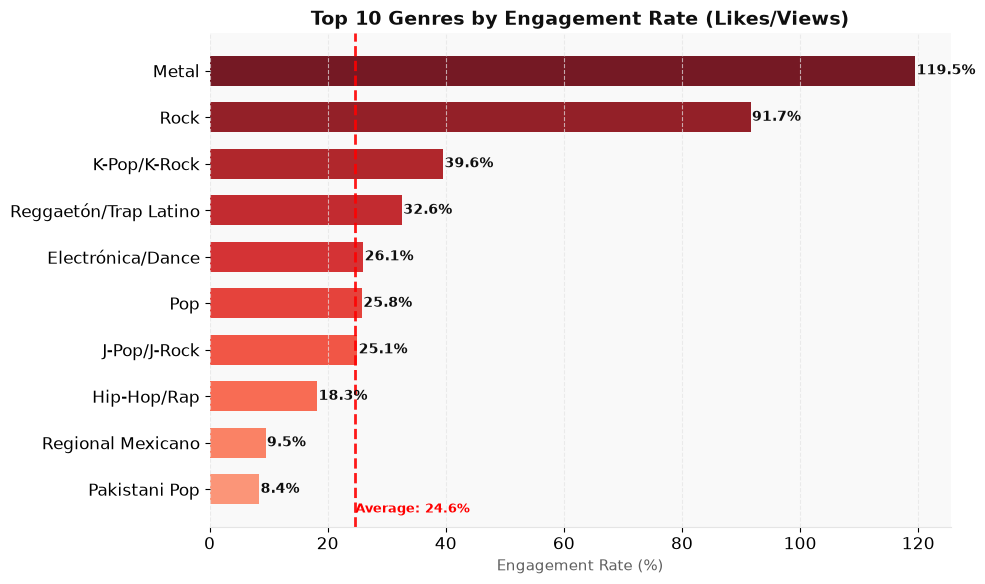

,Statistic,Value,Genre
0,Average,24.592353,
1,Median,9.530000,
2,Max,119.520000,Metal
3,Min,0.470000,OPM


In [9]:
engagement_chart = genre_stats.sort_values('engagement_rate', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_SURFACE)
colors = plt.cm.Reds(np.linspace(0.4, 1, len(engagement_chart)))[::-1]
bars = ax.barh(engagement_chart['macro_genre'], engagement_chart['engagement_rate'],
               color=colors, edgecolor='none', height=0.65, alpha=0.9)
ax.set_xlabel('Engagement Rate (%)', fontsize=11, color=YT_GRAY)
ax.set_title('Top 10 Genres by Engagement Rate (Likes/Views)', fontweight='bold', color=YT_TEXT, fontsize=14)
ax.invert_yaxis()
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color(YT_GRID)
ax.xaxis.grid(True, color=YT_GRID, linestyle='--', alpha=0.7)
for bar, val in zip(bars, engagement_chart['engagement_rate']):
    ax.text(val + 0.2, bar.get_y() + bar.get_height()/2, f'{val:.1f}%',
            va='center', fontsize=10, fontweight='bold', color=YT_TEXT)
avg_engagement = genre_stats['engagement_rate'].mean()
ax.axvline(x=avg_engagement, color=YT_RED, linestyle='--', linewidth=2, alpha=0.9)
ax.text(avg_engagement + 0.1, len(engagement_chart) - 0.5, f'Average: {avg_engagement:.1f}%',
        fontsize=9, color=YT_RED, fontweight='bold')
plt.tight_layout()
plt.show()

stats_summary = pd.DataFrame({
    'Statistic': ['Average', 'Median', 'Max', 'Min'],
    'Value': [avg_engagement, genre_stats['engagement_rate'].median(), genre_stats['engagement_rate'].max(), genre_stats['engagement_rate'].min()],
    'Genre': ['', '', genre_stats.loc[genre_stats['engagement_rate'].idxmax(), 'macro_genre'], genre_stats.loc[genre_stats['engagement_rate'].idxmin(), 'macro_genre']]
})
display(stats_summary)

### 5.4. Country-Genre Distribution Heatmap

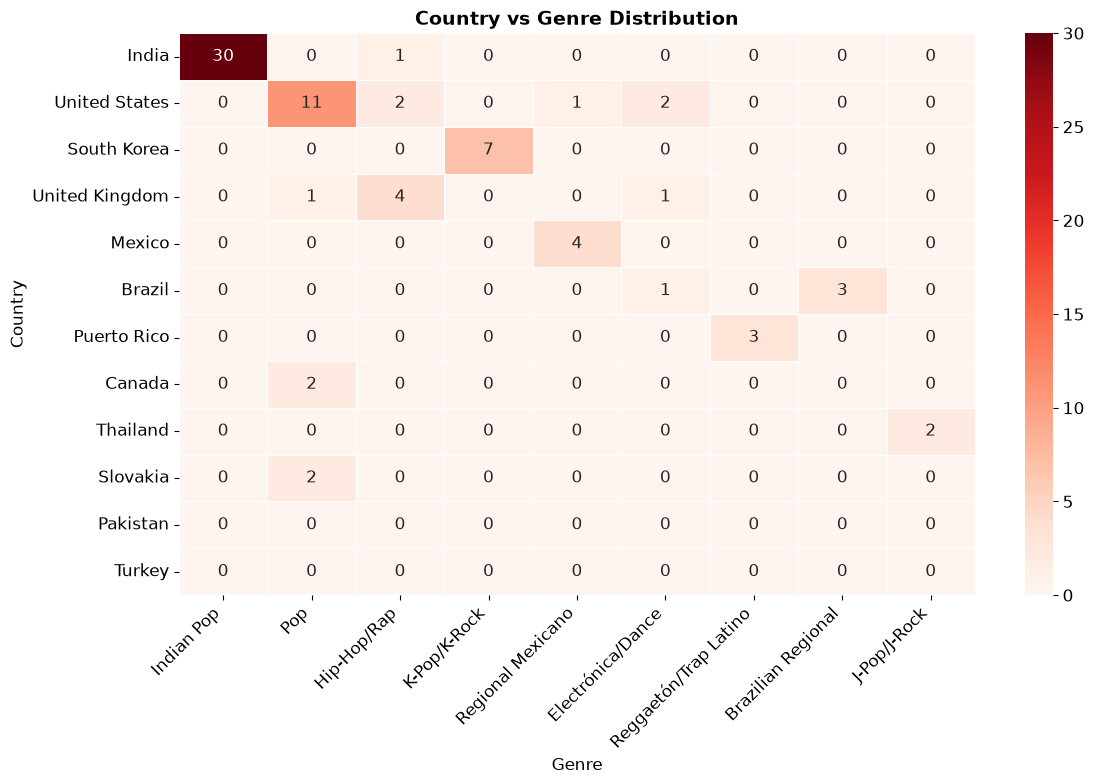

In [10]:
df_analysis = df[~df['artist_country'].isin(['Multi-country', 'Unknown'])]
if not df_analysis.empty:
    matrix = pd.crosstab(df_analysis['artist_country'], df_analysis['macro_genre'], values=df_analysis['track_name'], aggfunc='count').fillna(0)
    top_countries_h = matrix.sum(axis=1).sort_values(ascending=False).head(12).index
    top_genres = genre_stats.nlargest(10, 'total_songs')['macro_genre'].tolist()
    top_genres = [g for g in top_genres if g in matrix.columns]
    
    if len(top_countries_h) > 0 and len(top_genres) > 0:
        matrix_heatmap = matrix.loc[top_countries_h, top_genres].astype(int)
        plt.figure(figsize=(12, 8))
        sns.heatmap(matrix_heatmap, annot=True, fmt='d', cmap='Reds',
                    xticklabels=True, yticklabels=True, linewidths=0.5, linecolor='white')
        plt.title('Country vs Genre Distribution', fontsize=14, fontweight='bold')
        plt.xlabel('Genre', fontsize=12)
        plt.ylabel('Country', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.show()

## 6. Song Metrics

### 6.1. Top Songs by Views

In [11]:
display(df.nlargest(10, 'views')[['rank', 'track_name', 'artist_names', 'views', 'artist_country']])

,rank,track_name,artist_names,views,artist_country
0,1,Dai Dai,Shakira & Burna Boy,40661971,Colombia
1,2,Tu Mil Jaaye,Sachin-Jigar & Arijit Singh & Ed Sheeran & Mad...,37827726,India
2,3,POKITO,Daddy Yankee & Diljit Dosanjh,36123561,Puerto Rico
3,4,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,35997065,India
4,5,BbY WOW,KAROL G & Judeline & rusowsky,30531284,Spain
5,6,Alfaaz,Hamza Malik & Zain Zohaib,29896719,Pakistan
6,7,गुज़ारिश,Satinder Sartaaj,28263770,India
7,8,Пешта,Xamdam Sobirov,24191686,Uzbekistan
8,9,체포하겠어,ILLIT,23694267,South Korea
9,10,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23528049,India


### 6.2. Top Songs by Likes

In [12]:
display(df.nlargest(10, 'likes')[['rank', 'track_name', 'artist_names', 'likes', 'artist_country']])

,rank,track_name,artist_names,likes,artist_country
50,51,Gangnam Style (강남스타일),Psy,32383013,South Korea
30,31,Dame Tu Cosita (feat. Cutty Ranks),El Chombo,20970220,Panama
94,95,Love The Way You Lie (feat. Rihanna),Eminem,15369558,United States
86,87,Runaway,AURORA,13460586,Norway
39,40,Let Me Love You (feat. Justin Bieber),DJ Snake,12199796,France
60,61,Bring Me To Life,Evanescence,12072437,United States
22,23,Save Your Tears,The Weeknd,11135845,Canada
84,85,Poker Face,Lady Gaga,9040147,United States
0,1,Dai Dai,Shakira & Burna Boy,8878463,Colombia
66,67,November Rain,Guns N' Roses,8803207,United States


### 6.3. Top Songs by Engagement

In [13]:
display(df.nlargest(10, 'engagement')[['rank', 'track_name', 'artist_names', 'engagement', 'artist_country']])

,rank,track_name,artist_names,engagement,artist_country
50,51,Gangnam Style (강남스타일),Psy,287.59,South Korea
94,95,Love The Way You Lie (feat. Rihanna),Eminem,191.14,United States
86,87,Runaway,AURORA,160.18,Norway
30,31,Dame Tu Cosita (feat. Cutty Ranks),El Chombo,149.52,Panama
60,61,Bring Me To Life,Evanescence,119.52,United States
84,85,Poker Face,Lady Gaga,107.10,United States
39,40,Let Me Love You (feat. Justin Bieber),DJ Snake,96.58,France
66,67,November Rain,Guns N' Roses,91.66,United States
58,59,All I Want for Christmas Is You,Mariah Carey,72.35,United States
22,23,Save Your Tears,The Weeknd,69.71,Canada


## 7. Video Metrics

### 7.1. Video Summary

In [14]:
video_stats = {
    'Category': ['Official Videos', 'Lyric Videos', 'Live Performances', 'Collaborations'],
    'Count': [df['is_official_video'].sum(), df['is_lyric_video'].sum(), df['is_live_performance'].sum(), df['is_collaboration'].sum()]
}
v_stats_df = pd.DataFrame(video_stats)
v_stats_df['Percentage'] = (v_stats_df['Count'] / len(df) * 100).round(1).astype(str) + '%'
display(v_stats_df)

,Category,Count,Percentage
0,Official Videos,75,75.0%
1,Lyric Videos,53,53.0%
2,Live Performances,56,56.0%
3,Collaborations,19,19.0%


### 7.2. Views by Video Type

,Video Type,Total Videos,Avg Views,Median Views,Std Dev
0,Live,4,"13,210,918","13,094,758","3,796,085"
1,Lyric,16,"12,270,200","10,439,221","5,602,262"
2,Official,75,"14,185,320","11,595,019","7,415,718"
3,Other,5,"11,637,952","8,368,004","7,046,705"


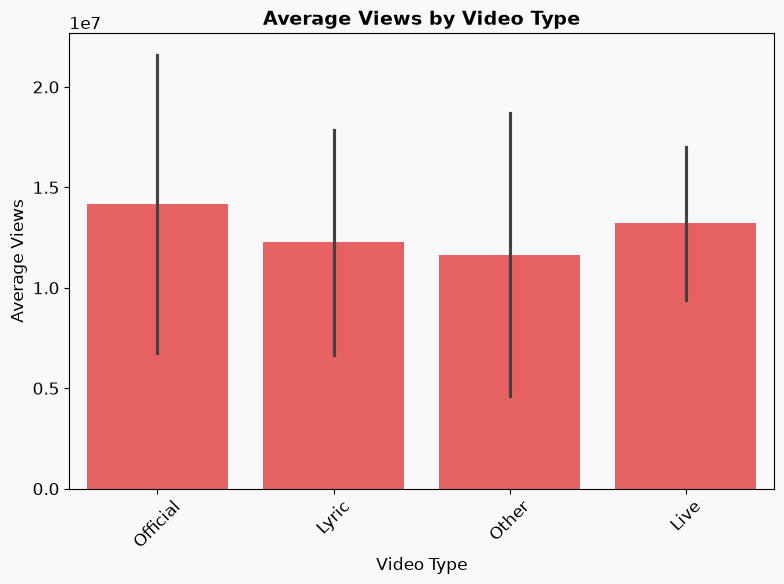

In [15]:
df_video = df.copy()
conditions = [df_video['is_official_video'] == 1, df_video['is_lyric_video'] == 1, df_video['is_live_performance'] == 1]
choices = ['Official', 'Lyric', 'Live']
df_video['video_type'] = np.select(conditions, choices, default='Other')
views_stats = df_video.groupby('video_type').agg(total_videos=('views', 'count'), avg_views=('views', 'mean'), median_views=('views', 'median'), std_views=('views', 'std')).round(2).reset_index()
table_views = views_stats.copy()
table_views['total_videos'] = table_views['total_videos'].astype(int)
table_views['avg_views'] = table_views['avg_views'].apply(lambda x: f'{x:,.0f}')
table_views['median_views'] = table_views['median_views'].apply(lambda x: f'{x:,.0f}')
table_views['std_views'] = table_views['std_views'].apply(lambda x: f'{x:,.0f}')
table_views.columns = ['Video Type', 'Total Videos', 'Avg Views', 'Median Views', 'Std Dev']
display(table_views)

fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor('#F9F9F9')
ax.set_facecolor('#F9F9F9')
sns.barplot(data=df_video, x='video_type', y='views', ax=ax, color='#FC4B4C', errorbar='sd')
ax.set_title('Average Views by Video Type', fontweight='bold', fontsize=14)
ax.set_ylabel('Average Views', fontsize=12)
ax.set_xlabel('Video Type', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 7.3. Engagement by Video Type

,Video Type,Avg Engagement (%)
0,Live,3.252500
1,Lyric,9.363750
2,Official,24.760933
3,Other,42.308000


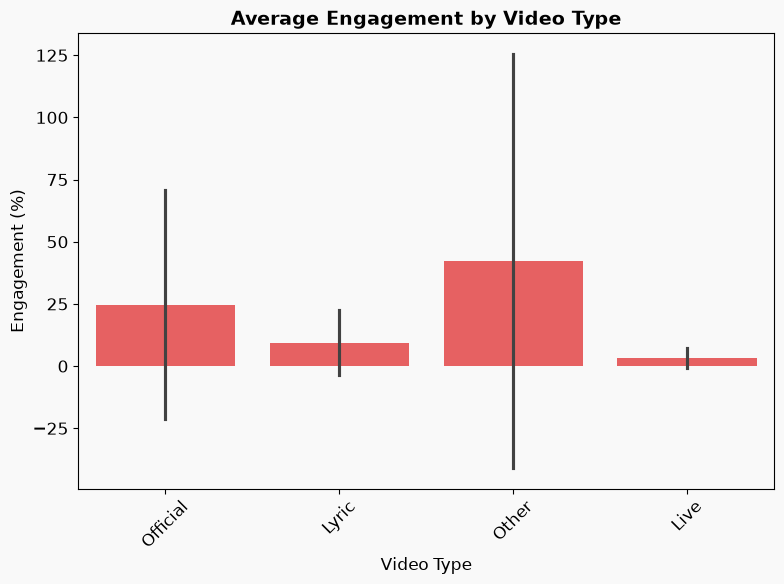

In [16]:
engagement_by_type = df_video.groupby('video_type')['engagement'].mean().reset_index()
engagement_by_type.columns = ['Video Type', 'Avg Engagement (%)']
display(engagement_by_type)

fig, ax = plt.subplots(figsize=(8, 6))
fig.patch.set_facecolor('#F9F9F9')
ax.set_facecolor('#F9F9F9')
sns.barplot(data=df_video, x='video_type', y='engagement', ax=ax, color='#FC4B4C', errorbar='sd')
ax.set_title('Average Engagement by Video Type', fontweight='bold', fontsize=14)
ax.set_ylabel('Engagement (%)', fontsize=12)
ax.set_xlabel('Video Type', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 7.4. Duration Analysis

,Statistic,Value
0,Average (min),3.7
1,Minimum (s),81
2,Maximum (s),557
3,Median (s),214.5
4,Q1 (min),3.0
5,Q3 (min),4.0


/tmp/ipykernel_2283/3066596533.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = ax2.boxplot(duration_minutes, vert=False, patch_artist=True, widths=0.6,


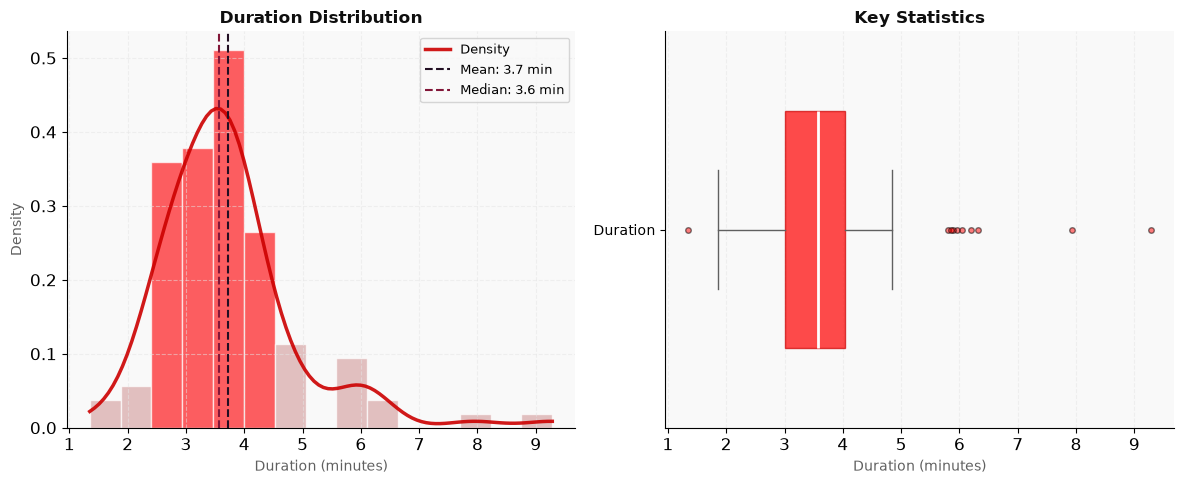

In [17]:
duration_minutes = df['duration_s'] / 60
dur_stats = pd.DataFrame({
    'Statistic': ['Average (min)', 'Minimum (s)', 'Maximum (s)', 'Median (s)', 'Q1 (min)', 'Q3 (min)'],
    'Value': [f'{duration_minutes.mean():.1f}', f'{df["duration_s"].min()}', f'{df["duration_s"].max()}', f'{df["duration_s"].median()}', f'{duration_minutes.quantile(0.25):.1f}', f'{duration_minutes.quantile(0.75):.1f}']
})
display(dur_stats)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(YT_BG)
ax1 = axes[0]
ax1.set_facecolor(YT_SURFACE)
n, bins, patches = ax1.hist(duration_minutes, bins=15, edgecolor='white', alpha=0.7, density=True)
for patch in patches:
    patch.set_facecolor('#FE1B1F' if patch.get_height() > 0.2 else '#D8A7A7')
kde = gaussian_kde(duration_minutes)
x = np.linspace(duration_minutes.min(), duration_minutes.max(), 100)
ax1.plot(x, kde(x), color=YT_RED_DARK, linewidth=2.5, label='Density', alpha=0.9)
ax1.axvline(duration_minutes.mean(), color='#220F23', linestyle='--', linewidth=1.5, label=f'Mean: {duration_minutes.mean():.1f} min')
ax1.axvline(duration_minutes.median(), color='#821638', linestyle='--', linewidth=1.5, label=f'Median: {duration_minutes.median():.1f} min')
ax1.set_xlabel('Duration (minutes)', fontsize=10, color=YT_GRAY)
ax1.set_ylabel('Density', fontsize=10, color=YT_GRAY)
ax1.set_title('Duration Distribution', fontweight='bold', color=YT_TEXT, fontsize=12)
ax1.legend(loc='upper right', fontsize=9, facecolor=YT_SURFACE)
ax1.spines[['top', 'right']].set_visible(False)
ax1.grid(True, color=YT_GRID, linestyle='--', alpha=0.5)
ax2 = axes[1]
ax2.set_facecolor(YT_SURFACE)
bp = ax2.boxplot(duration_minutes, vert=False, patch_artist=True, widths=0.6,
                 boxprops=dict(facecolor=YT_RED, color=YT_RED_DARK, alpha=0.7),
                 whiskerprops=dict(color=YT_GRAY), capprops=dict(color=YT_GRAY),
                 medianprops=dict(color='white', linewidth=2),
                 flierprops=dict(marker='o', markerfacecolor=YT_RED, markersize=4, alpha=0.5))
ax2.set_yticks([1])
ax2.set_yticklabels(['Duration'], fontsize=10)
ax2.set_xlabel('Duration (minutes)', fontsize=10, color=YT_GRAY)
ax2.set_title('Key Statistics', fontweight='bold', color=YT_TEXT, fontsize=12)
ax2.spines[['top', 'right']].set_visible(False)
ax2.grid(True, color=YT_GRID, linestyle='--', alpha=0.5, axis='x')
plt.tight_layout()
plt.show()

### 7.5. Channel Type Distribution

,Channel Type,Count,Percentage
0,General,51,51.0%
1,Label/Studio,28,28.0%
2,VEVO,18,18.0%
3,User Channel,1,1.0%
4,Artist Channel,1,1.0%
5,Topic,1,1.0%


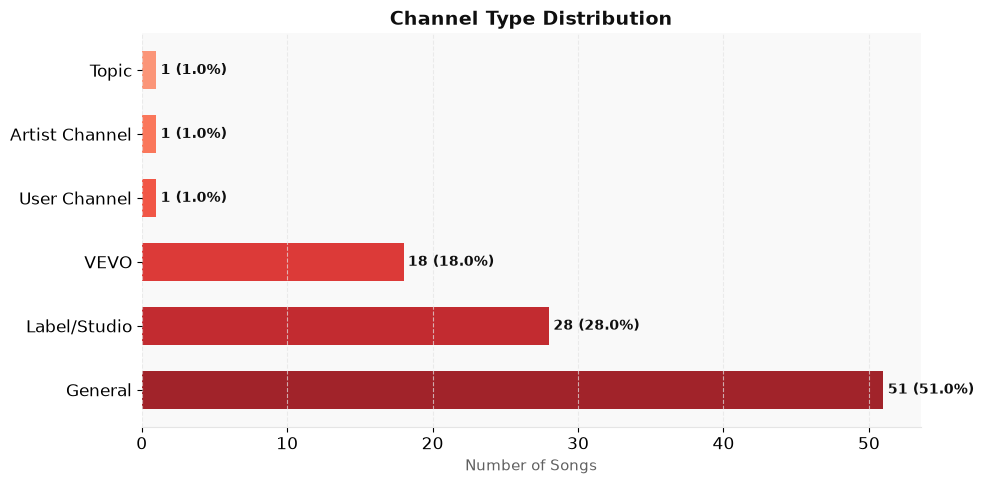

In [18]:
channel_counts = df['channel_type'].value_counts()
ch_df = pd.DataFrame({'Channel Type': channel_counts.index, 'Count': channel_counts.values})
ch_df['Percentage'] = (ch_df['Count'] / len(df) * 100).round(1).astype(str) + '%'
display(ch_df)

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_SURFACE)
colors = plt.cm.Reds(np.linspace(0.4, 0.9, len(channel_counts)))[::-1]
bars = ax.barh(channel_counts.index, channel_counts.values, color=colors, edgecolor='none', height=0.6, alpha=0.9)
ax.set_xlabel('Number of Songs', fontsize=11, color=YT_GRAY)
ax.set_title('Channel Type Distribution', fontweight='bold', color=YT_TEXT, fontsize=14)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color(YT_GRID)
ax.xaxis.grid(True, color=YT_GRID, linestyle='--', alpha=0.7)
for bar, val in zip(bars, channel_counts.values):
    ax.text(val + 0.3, bar.get_y() + bar.get_height()/2, f'{val} ({val/len(df)*100:.1f}%)', va='center', fontsize=10, fontweight='bold', color=YT_TEXT)
plt.tight_layout()
plt.show()

## 8. Temporal Analysis

In [19]:
bg_color = '#F9F9F9'
genre_palette = ['#751924', '#FF0000', '#282828', '#FFB347', '#FF6B6B']
top5_genres = genre_stats.nlargest(5, 'total_songs')['macro_genre'].tolist()
df_temporal = df[df['macro_genre'].isin(top5_genres)].copy()
temporal_views = df_temporal.groupby(['upload_quarter', 'macro_genre'])['views'].sum().reset_index()
temporal_engagement = df_temporal.groupby(['upload_quarter', 'macro_genre'])['engagement'].mean().reset_index()

### 8.1. Views Evolution by Quarter

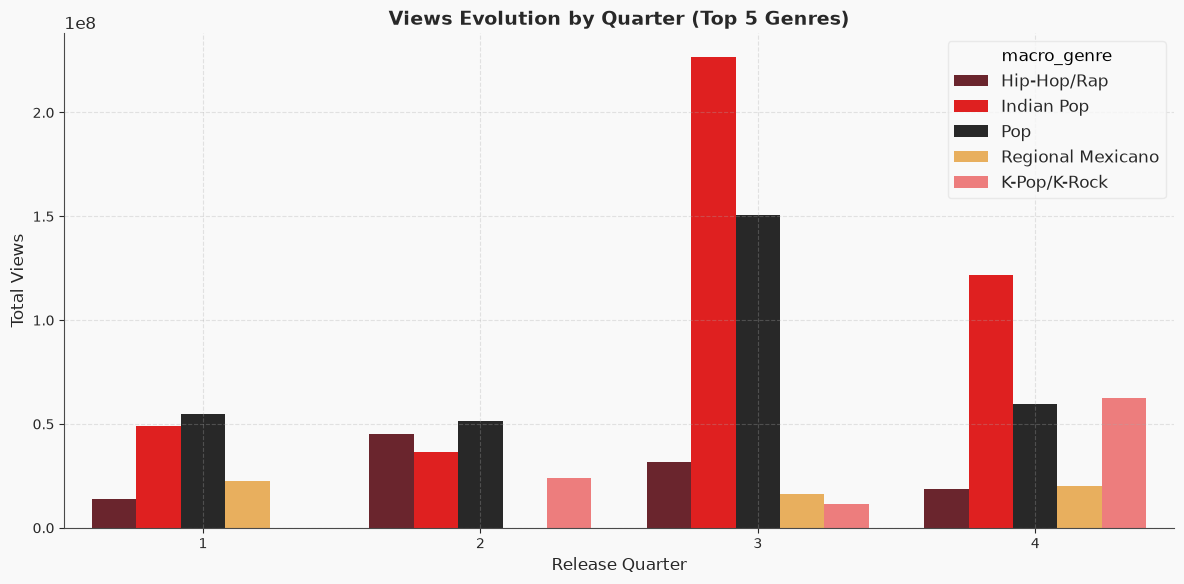

In [20]:
fig1, ax1 = plt.subplots(figsize=(12, 6), facecolor=bg_color)
ax1.set_facecolor(bg_color)
sns.barplot(data=temporal_views, x='upload_quarter', y='views', hue='macro_genre', palette=genre_palette, ax=ax1)
ax1.set_title('Views Evolution by Quarter (Top 5 Genres)', fontweight='bold', color='#282828', fontsize=14)
ax1.set_xlabel('Release Quarter', color='#282828', fontsize=12)
ax1.set_ylabel('Total Views', color='#282828', fontsize=12)
ax1.tick_params(colors='#282828', labelsize=10)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_color('#4A4A4A')
ax1.spines['bottom'].set_color('#4A4A4A')
ax1.grid(True, linestyle='--', alpha=0.3, color='#AAAAAA')
legend1 = ax1.get_legend()
if legend1:
    legend1.get_frame().set_facecolor(bg_color)
    legend1.get_frame().set_edgecolor('#E5E5E5')
    for text in legend1.get_texts(): text.set_color('#282828')
plt.tight_layout()
plt.show()

### 8.2. Engagement Evolution by Quarter

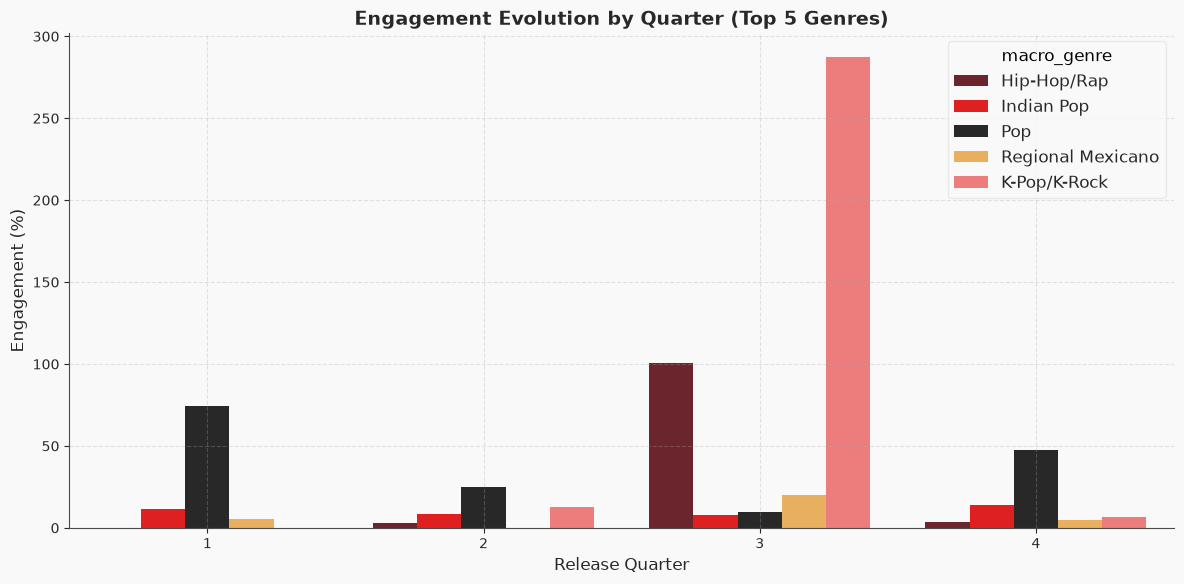

In [21]:
fig2, ax2 = plt.subplots(figsize=(12, 6), facecolor=bg_color)
ax2.set_facecolor(bg_color)
sns.barplot(data=temporal_engagement, x='upload_quarter', y='engagement', hue='macro_genre', palette=genre_palette, ax=ax2)
ax2.set_title('Engagement Evolution by Quarter (Top 5 Genres)', fontweight='bold', color='#282828', fontsize=14)
ax2.set_xlabel('Release Quarter', color='#282828', fontsize=12)
ax2.set_ylabel('Engagement (%)', color='#282828', fontsize=12)
ax2.tick_params(colors='#282828', labelsize=10)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_color('#4A4A4A')
ax2.spines['bottom'].set_color('#4A4A4A')
ax2.grid(True, linestyle='--', alpha=0.3, color='#AAAAAA')
legend2 = ax2.get_legend()
if legend2:
    legend2.get_frame().set_facecolor(bg_color)
    legend2.get_frame().set_edgecolor('#E5E5E5')
    for text in legend2.get_texts(): text.set_color('#282828')
plt.tight_layout()
plt.show()

### 8.3. Release Distribution by Quarter

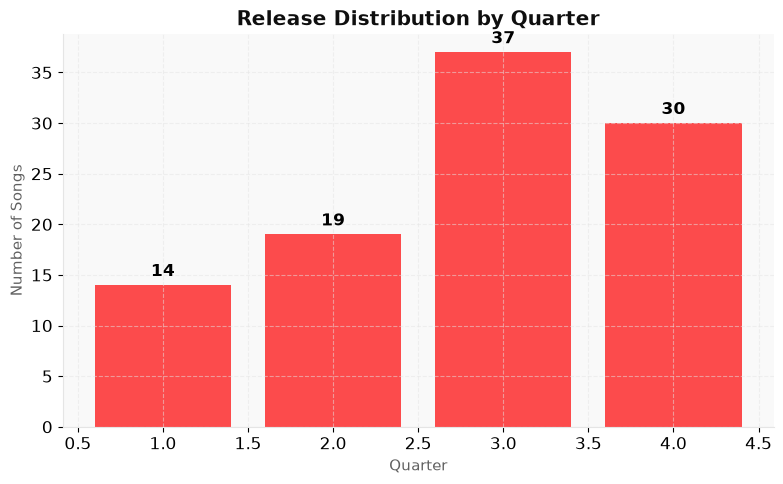

In [22]:
season_counts = df['upload_quarter'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(YT_BG)
ax.set_facecolor(YT_SURFACE)
bars = ax.bar(season_counts.index, season_counts.values, color='#FC4B4C', edgecolor='none')
ax.set_xlabel('Quarter', fontsize=11, color=YT_GRAY)
ax.set_ylabel('Number of Songs', fontsize=11, color=YT_GRAY)
ax.set_title('Release Distribution by Quarter', fontweight='bold', color=YT_TEXT)
ax.spines[['top', 'right']].set_visible(False)
ax.spines['bottom'].set_color(YT_GRID)
ax.spines['left'].set_color(YT_GRID)
ax.grid(True, color=YT_GRID, linestyle='--', alpha=0.5)
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.5, f'{int(height)}', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

## 9. Collaborations Analysis

,is_collaboration,count,avg_views,avg_engagement
0,Solo,81,"13,684,138",17.93%
1,Collaboration,19,"13,833,708",40.99%


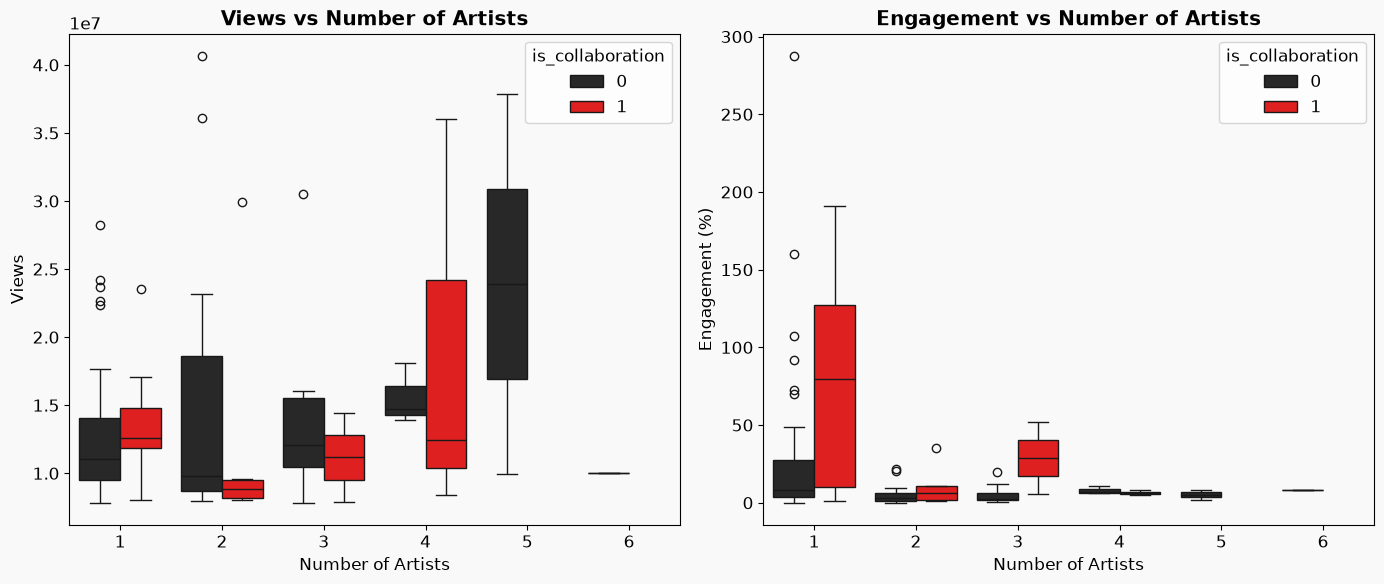

In [23]:
collab_stats = df.groupby('is_collaboration').agg(
    count=('track_name', 'count'),
    avg_views=('views', 'mean'),
    avg_engagement=('engagement', 'mean')
).reset_index()
collab_stats['is_collaboration'] = collab_stats['is_collaboration'].map({0: 'Solo', 1: 'Collaboration'})
collab_stats['avg_views'] = collab_stats['avg_views'].apply(lambda x: f'{x:,.0f}')
collab_stats['avg_engagement'] = collab_stats['avg_engagement'].round(2).astype(str) + '%'
display(collab_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor('#F9F9F9')
axes[0].set_facecolor('#F9F9F9')
axes[1].set_facecolor('#F9F9F9')
sns.boxplot(data=df, x='artist_count', y='views', hue='is_collaboration', palette={0: '#282828', 1: 'red'}, ax=axes[0])
axes[0].set_title('Views vs Number of Artists', fontweight='bold')
axes[0].set_xlabel('Number of Artists')
axes[0].set_ylabel('Views')
sns.boxplot(data=df, x='artist_count', y='engagement', hue='is_collaboration', palette={0: '#282828', 1: 'red'}, ax=axes[1])
axes[1].set_title('Engagement vs Number of Artists', fontweight='bold')
axes[1].set_xlabel('Number of Artists')
axes[1].set_ylabel('Engagement (%)')
plt.tight_layout()
plt.show()

## 10. Executive Summary

In [24]:
stats = general_stats(df)
print(f"Songs: {stats['total_songs']}")
print(f"Countries: {stats['unique_countries']}")
print(f"Genres: {stats['unique_genres']}")
print(f"Total views: {format_number(stats['total_views'])}")
print(f"Total likes: {format_number(stats['total_likes'])}")
print(f"Avg engagement: {stats['avg_engagement']:.2f}%")

Songs: 100
Countries: 26
Genres: 17
Total views: 1.4B
Total likes: 253.8M
Avg engagement: 22.31%
